# Landsat summer surface temperature and provisional friction
June–August 2025; actual overpass observations around noon. This is not air temperature or daily maximum heat. Cached scene data are reused. Run All with Python (EmPath).

In [1]:
from pathlib import Path
import sys,json
ROOT=Path.cwd()
if not (ROOT/'scripts').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))

In [2]:
REBUILD=False
from landsat_summer_heat import main as process_heat
if REBUILD or not (ROOT/'output/landsat_heat/method_and_coverage.json').exists():process_heat()
display(json.loads((ROOT/'output/landsat_heat/method_and_coverage.json').read_text()))

{'source': 'USGS Landsat Collection 2 Level-2 Tier 1 Surface Temperature (Landsat 8/9), accessed via Microsoft Planetary Computer',
 'period': '2025-06-01 through 2025-08-31',
 'scenes': 11,
 'unique_acquisition_dates': 11,
 'local_acquisition_times': ['2025-08-24T12:02:19.679585-05:00',
  '2025-08-16T12:02:15.308672-05:00',
  '2025-08-08T12:02:12.939181-05:00',
  '2025-07-31T12:02:06.329213-05:00',
  '2025-07-23T12:02:04.026441-05:00',
  '2025-07-15T12:02:02.021674-05:00',
  '2025-07-07T12:01:55.829720-05:00',
  '2025-06-29T12:01:57.661356-05:00',
  '2025-06-21T12:01:51.475500-05:00',
  '2025-06-13T12:01:49.310527-05:00',
  '2025-06-05T12:01:36.768716-05:00'],
 'scale_formula_celsius': 'DN * 0.00341802 + 149 - 273.15',
 'qa_policy': 'Mask QA_PIXEL bits 0–5, medium/high cloud and cirrus confidence, ST_QA > 3 K, distance to cloud < 1 km; keep water unless separately masked by QA. Require >=3 valid acquisition dates per pixel.',
 'native_thermal_resolution_m': 100,
 'delivered_grid_m': 3

## Three-factor scenario
100 × [min–max normalized block surface temperature + existing traffic index/100 + (1 − AI canopy percent/100)] / 3. Equal assumed weights; temperature and canopy can be correlated. Missing required factors remain unknown. Temperature normalization references valid blocks in the four-ZIP pilot; traffic retains its Plano city reference. This changes the provisional block map, not the already calculated illustrative route costs.

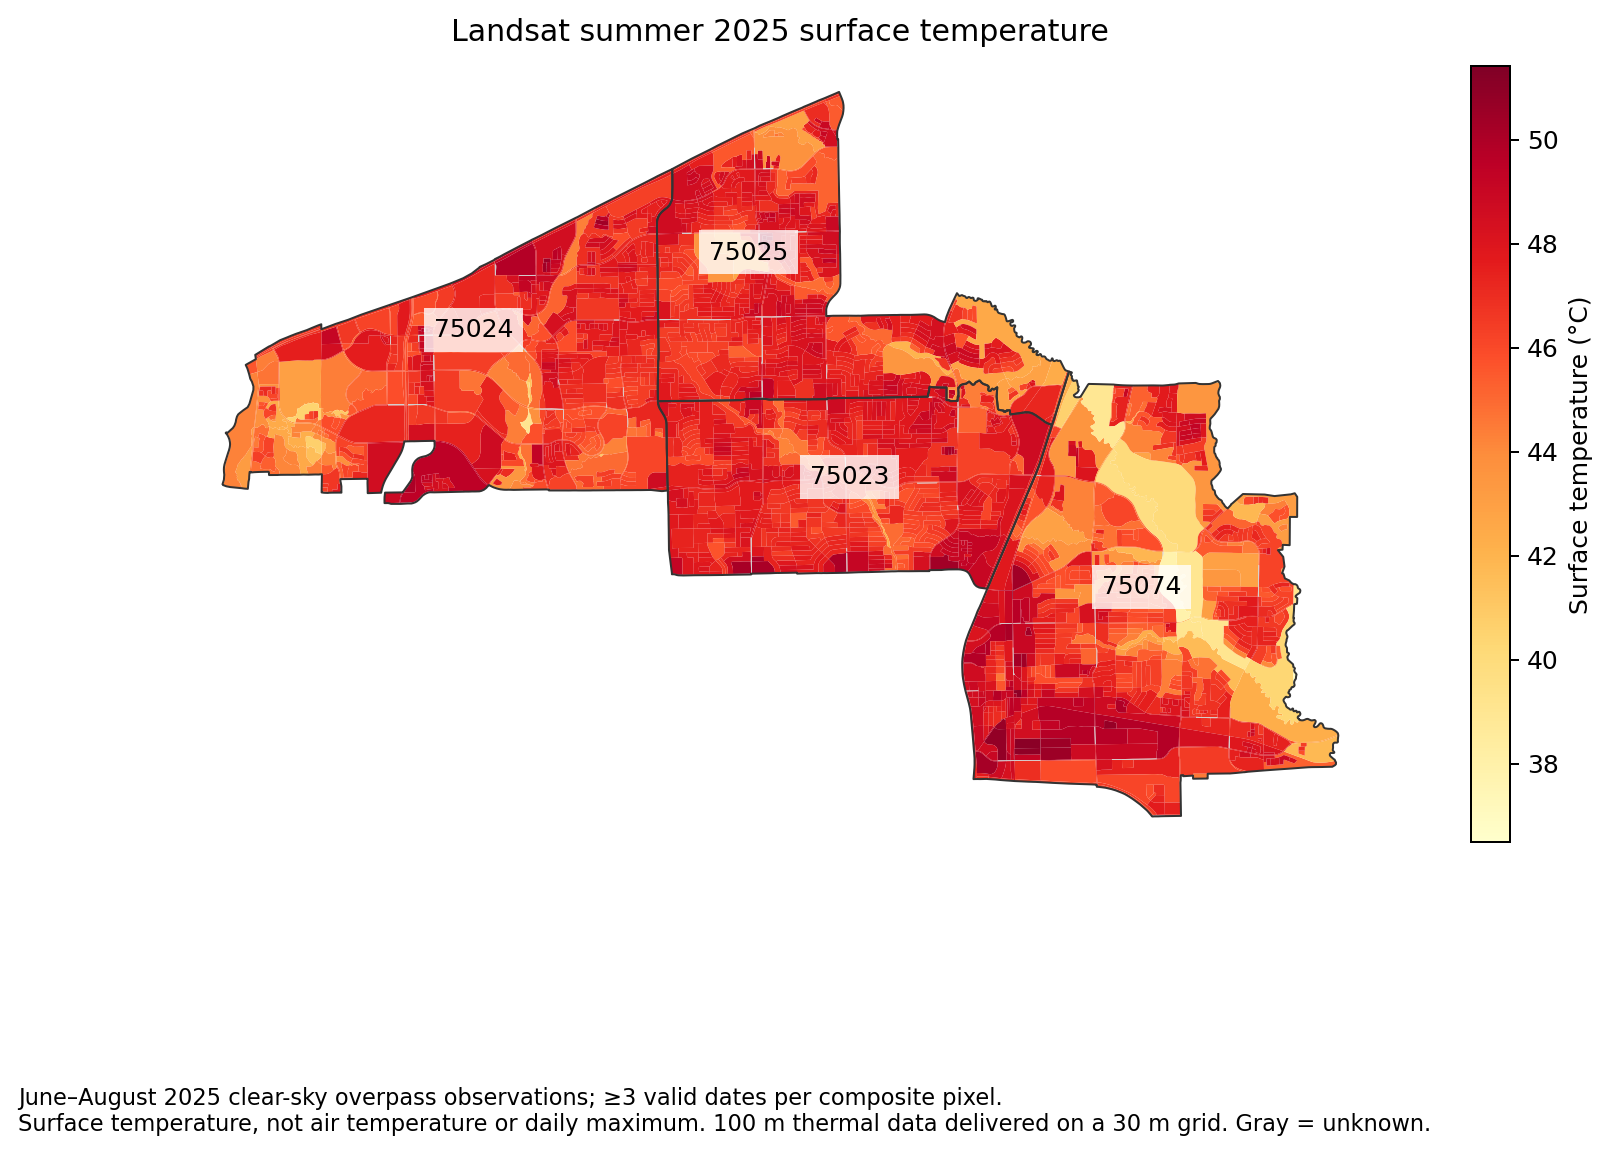

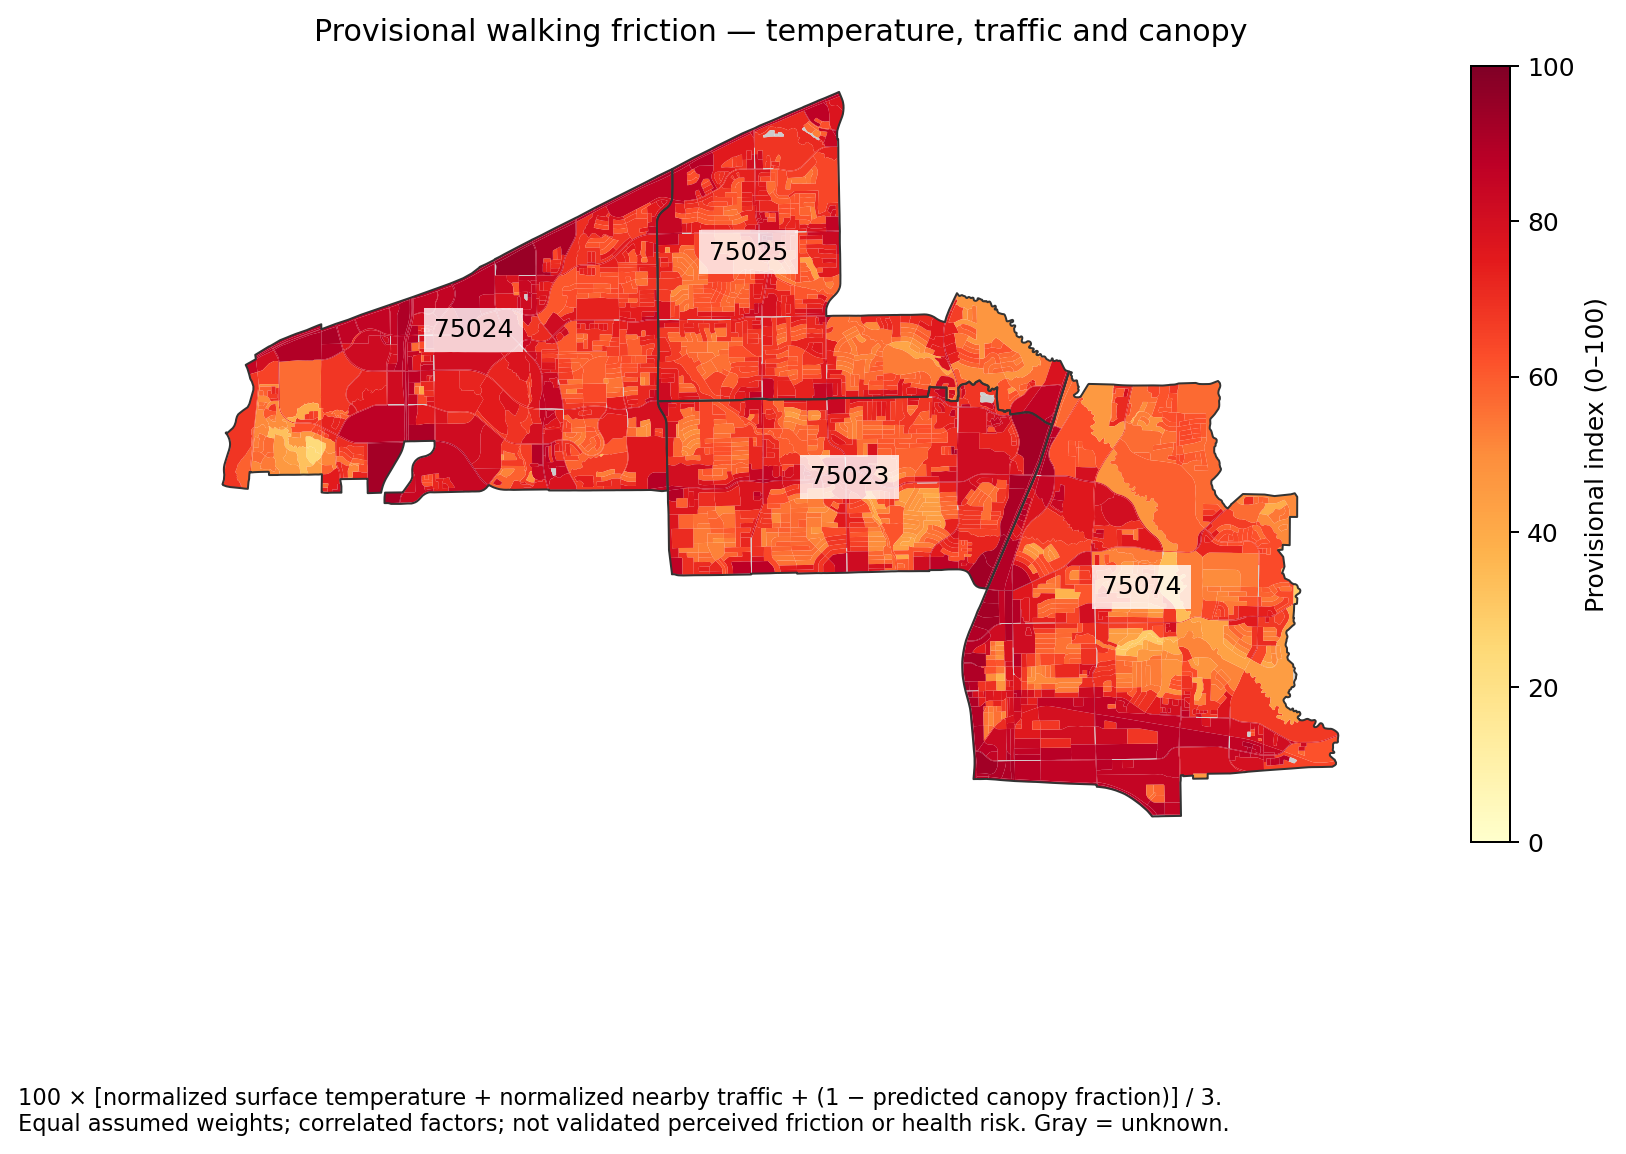

In [3]:
from landsat_map_layer import figures
from IPython.display import Image,display
for r in figures():display(Image(filename=str(ROOT/'output/landsat_heat'/r['image']),width=900))

## Outputs and limitations
GeoTIFF temperature and valid-date counts; block_environment_with_heat.gpkg/CSV; added heat fields in both current block GeoPackages; scene manifest; QA/coverage report; index-method JSON; map PNGs. Thermal detail is approximately 100 m, delivered on a 30 m grid. Gray means unknown, including small blocks without pixel centers. No health-risk or comfort validation.

Sources: https://www.usgs.gov/landsat-missions/landsat-collection-2-surface-temperature and https://www.usgs.gov/landsat-missions/landsat-collection-2-quality-assessment-bands